<a href="https://colab.research.google.com/github/alanasena/sentimento-avaliacoes-ptbr/blob/main/projeto_sentimento.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

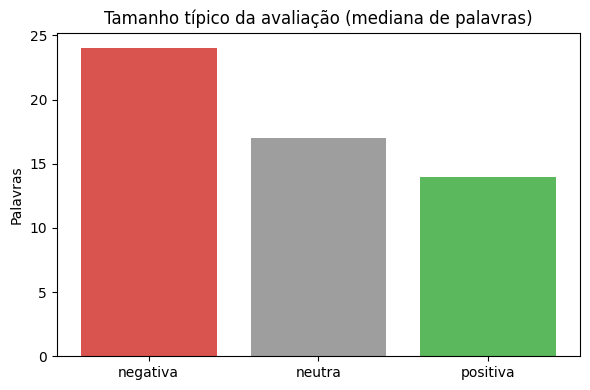

In [8]:
dados["palavras"] = dados["texto"].str.split().str.len()
mediana = dados.groupby("sentimento")["palavras"].median().reindex(ordem)

plt.figure(figsize=(6, 4))
plt.bar(mediana.index, mediana.values, color=cores)
plt.title("Tamanho típico da avaliação (mediana de palavras)")
plt.ylabel("Palavras")
plt.tight_layout()
plt.savefig("grafico_tamanho.png", dpi=150)
plt.show()

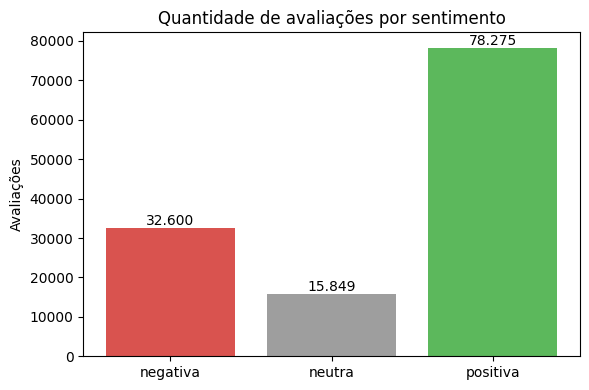

In [7]:
import matplotlib.pyplot as plt

ordem = ["negativa", "neutra", "positiva"]
cores = ["#d9534f", "#9e9e9e", "#5cb85c"]

contagem = dados["sentimento"].value_counts().reindex(ordem)

plt.figure(figsize=(6, 4))
plt.bar(contagem.index, contagem.values, color=cores)
plt.title("Quantidade de avaliações por sentimento")
plt.ylabel("Avaliações")
for i, v in enumerate(contagem.values):
    plt.text(i, v, f"{v:,}".replace(",", "."), ha="center", va="bottom")
plt.tight_layout()
plt.savefig("grafico_sentimentos.png", dpi=150)
plt.show()

In [6]:
def nota_para_sentimento(nota):
    if nota <= 2:
        return "negativa"
    elif nota == 3:
        return "neutra"
    else:
        return "positiva"

dados["sentimento"] = dados["nota"].apply(nota_para_sentimento)

dados["sentimento"].value_counts()

,count
sentimento,
positiva,78275
negativa,32600
neutra,15849


In [5]:
dados = dados.dropna(subset=["texto"])
dados["texto"] = dados["texto"].str.strip()
dados = dados[dados["texto"].str.len() >= 10]
dados = dados.drop_duplicates(subset=["texto"])

print("Depois da limpeza:", len(dados))

Depois da limpeza: 126724


In [4]:
dados = df[["review_text", "overall_rating"]].copy()
dados.columns = ["texto", "nota"]

print("Antes da limpeza:", len(dados))

Antes da limpeza: 132373


In [3]:
df["overall_rating"].value_counts().sort_index()

,count
overall_rating,
1,27369
2,8389
3,16315
4,32345
5,47955


In [2]:
df[["review_text", "overall_rating"]].sample(5, random_state=42)

,review_text,overall_rating
328,"Ele e muito bom ,bom, bom , bom , bom. BOM BOM...",5
83773,cumpre a funcao desejada melhor que a marca co...,4
117905,Não tem luz então não funciona a noite. Sem ma...,1
47675,"Lindo painel,material de qualidade,forte e res...",4
51037,Muito boa a lente estabilização e foco m...,5


In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/americanas-tech/b2w-reviews01/main/B2W-Reviews01.csv"
df = pd.read_csv(url, low_memory=False)

print(df.shape)
df.head()

(132373, 14)


,submission_date,reviewer_id,product_id,product_name,product_brand,site_category_lv1,site_category_lv2,review_title,overall_rating,recommend_to_a_friend,review_text,reviewer_birth_year,reviewer_gender,reviewer_state
0,2018-01-01 00:11:28,d0fb1ca69422530334178f5c8624aa7a99da47907c44de...,132532965,Notebook Asus Vivobook Max X541NA-GO472T Intel...,NaN,Informática,Notebook,Bom,4,Yes,Estou contente com a compra entrega rápida o ú...,1958.0,F,RJ
1,2018-01-01 00:13:48,014d6dc5a10aed1ff1e6f349fb2b059a2d3de511c7538a...,22562178,Copo Acrílico Com Canudo 500ml Rocie,NaN,Utilidades Domésticas,"Copos, Taças e Canecas","Preço imbatível, ótima qualidade",4,Yes,"Por apenas R$1994.20,eu consegui comprar esse ...",1996.0,M,SC
2,2018-01-01 00:26:02,44f2c8edd93471926fff601274b8b2b5c4824e386ae4f2...,113022329,Panela de Pressão Elétrica Philips Walita Dail...,philips walita,Eletroportáteis,Panela Elétrica,ATENDE TODAS AS EXPECTATIVA.,4,Yes,SUPERA EM AGILIDADE E PRATICIDADE OUTRAS PANEL...,1984.0,M,SP
3,2018-01-01 00:35:54,ce741665c1764ab2d77539e18d0e4f66dde6213c9f0863...,113851581,Betoneira Columbus - Roma Brinquedos,roma jensen,Brinquedos,Veículos de Brinquedo,presente mais que desejado,4,Yes,MEU FILHO AMOU! PARECE DE VERDADE COM TANTOS D...,1985.0,F,SP
4,2018-01-01 01:00:28,7d7b6b18dda804a897359276cef0ca252f9932bf4b5c8e...,131788803,"Smart TV LED 43"" LG 43UJ6525 Ultra HD 4K com C...",lg,TV e Home Theater,TV,"Sem duvidas, excelente",5,Yes,"A entrega foi no prazo, as americanas estão de...",1994.0,M,MG
